### Investor access recommender

##### Paul Taiwo-Adeyemo, November 2026

##### Notebook #2 - Modelling

### Modelling

This notebook continues from Notebook #1. It uses the cleaned buys to suggest assets a customer has not bought yet.

###### Order of analysis

>1. Load the cleaned buys

>2. Split them by date

>3. Fit popularity and item-item

>4. Compare the two lists with recall@10 and nDCG@10

The models only see buys from before 30 May 2022. The test window is 30 May 2022 up to 30 Nov 2022.

A hit is the first time a customer buys an asset in that window. Buying something they already held does not count. Customers with no buys before the cutoff are left out, because there is nothing to base a list on.

In [1]:
#import the packages used for modelling
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
#same chart style as notebook 1
plt.style.use("tableau-colorblind10")

In [3]:
#load the cleaned buys
buys = pd.read_csv("data/processed/buys.csv")
buys["timestamp"] = pd.to_datetime(buys["timestamp"])
buys.head()

,customerID,ISIN,timestamp
0,DF82411CCBF6BCCC6609,GRS015003007,2018-01-02
1,A9F4B9BBAFD66BFF74C6,GRF000031002,2018-01-02
2,C025D680ABF96DBDEA4A,GRS003003035,2018-01-02
3,C01D3D52B80831619E0C,GRS003003035,2018-01-02
4,C01AB2A98E98D198546B,GRS003003035,2018-01-02


In [4]:
#history is everything before the cutoff, the test window is the six months after it
cutoff = pd.Timestamp("2022-05-30")
end = pd.Timestamp("2022-11-30")

history = buys[buys["timestamp"] < cutoff]
window = buys[(buys["timestamp"] >= cutoff) & (buys["timestamp"] < end)]
history.shape, window.shape

((196332, 3), (17141, 3))

In [5]:
#first-time buys in the test window, for customers who already had a history
seen = set(zip(history["customerID"], history["ISIN"]))

targets = {}
for customer, isin in zip(window["customerID"], window["ISIN"]):
    if (customer, isin) not in seen:
        targets.setdefault(customer, set()).add(isin)

known = set(history["customerID"])
customers = sorted(customer for customer in targets if customer in known)
targets = {customer: targets[customer] for customer in customers}

held = history.groupby("customerID")["ISIN"].agg(set).to_dict()
len(customers)

1686

1,686 customers bought something new in the test window and also had at least one buy before it. The scores below are the average over these customers.

#### Popularity

Suggest the assets that the most customers bought before the cutoff. Assets the customer already bought are left off the list.

In [6]:
#number of customers who bought each asset before the cutoff
popularity_scores = history.groupby("ISIN")["customerID"].nunique().astype(float)
popularity_scores.sort_values(ascending=False).head(10)

ISIN
GRS003003035    7997.0
GRS015003007    4384.0
GRS260333000    3256.0
GRS014003032    2632.0
GRF000037009    2617.0
GRS323003012    2557.0
GRS434003000    2398.0
GRC5091217D9    2095.0
GRS298343005    2047.0
GRS393503008    2026.0
Name: customerID, dtype: float64

In [7]:
#top 10 assets the customer has not already bought
def top10(scores, customer):
    already = held.get(customer, set())
    kept = scores.drop(labels=[isin for isin in already if isin in scores.index])
    return list(kept.sort_values(ascending=False).head(10).index)

popularity_lists = {customer: top10(popularity_scores, customer) for customer in customers}

#### Item-item

If two assets were bought by the same customers, they get a high similarity. A customer's list is the assets most similar to the ones they already hold.

In [8]:
#one row per customer and asset, 1 if they bought it before the cutoff
pairs = history[["customerID", "ISIN"]].drop_duplicates()
pairs["bought"] = 1.0
user_item = pairs.pivot_table(index="customerID", columns="ISIN", values="bought", aggfunc="max")
user_item = user_item.fillna(0.0)
user_item.shape

(27648, 308)

In [9]:
#cosine similarity between assets
matrix = user_item.to_numpy()
norms = np.linalg.norm(matrix, axis=0)
norms[norms == 0] = 1
similarity = (matrix.T @ matrix) / np.outer(norms, norms)
np.fill_diagonal(similarity, 0)

asset_names = list(user_item.columns)
similarity = pd.DataFrame(similarity, index=asset_names, columns=asset_names)

In [10]:
#score every test customer, then take the top 10 they do not already hold
held_matrix = user_item.reindex(customers).fillna(0.0)
item_scores = pd.DataFrame(
    held_matrix.to_numpy() @ similarity.to_numpy(),
    index=customers,
    columns=asset_names,
)

item_lists = {customer: top10(item_scores.loc[customer], customer) for customer in customers}

#### Scores

Recall@10 is the share of the new buys that showed up in the top 10.

nDCG@10 gives more credit when the right asset is closer to the top of the list.

In [11]:
#recall@10 and nDCG@10 for one list
def recall_at_10(recommended, relevant):
    return len(set(recommended[:10]) & relevant) / len(relevant)

def ndcg_at_10(recommended, relevant):
    gained = 0
    for rank, isin in enumerate(recommended[:10]):
        if isin in relevant:
            gained += 1 / np.log2(rank + 2)
    ideal = sum(1 / np.log2(rank + 2) for rank in range(min(10, len(relevant))))
    return gained / ideal

In [12]:
#average the two scores over the test customers
def average_scores(lists):
    recall = np.mean([recall_at_10(lists[customer], targets[customer]) for customer in customers])
    ndcg = np.mean([ndcg_at_10(lists[customer], targets[customer]) for customer in customers])
    return recall, ndcg

popularity_recall, popularity_ndcg = average_scores(popularity_lists)
item_recall, item_ndcg = average_scores(item_lists)

print(f"Popularity  recall@10 {popularity_recall:.3f}   nDCG@10 {popularity_ndcg:.3f}")
print(f"Item-item   recall@10 {item_recall:.3f}   nDCG@10 {item_ndcg:.3f}")

Popularity  recall@10 0.223   nDCG@10 0.128
Item-item   recall@10 0.272   nDCG@10 0.177


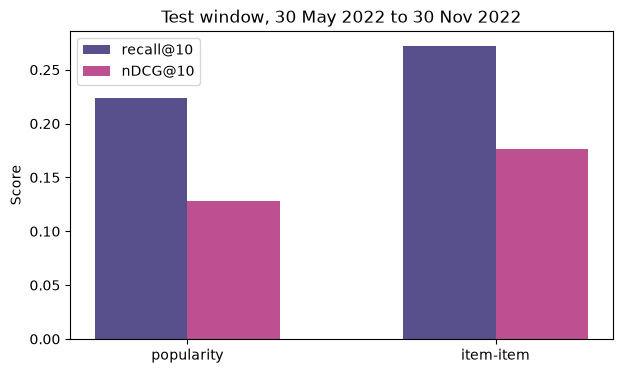

In [13]:
#plot the two models
labels = ["popularity", "item-item"]
x = np.arange(len(labels))

plt.figure(figsize=(7, 4))
plt.bar(x - 0.15, [popularity_recall, item_recall], width=0.3, label="recall@10", color="#58508d")
plt.bar(x + 0.15, [popularity_ndcg, item_ndcg], width=0.3, label="nDCG@10", color="#bc5090")
plt.xticks(x, labels)
plt.ylabel("Score")
plt.title("Test window, 30 May 2022 to 30 Nov 2022")
plt.legend()
plt.show()

Item-item did better than popularity on both scores. Recall@10 was 0.272 against 0.223. nDCG@10 was 0.177 against 0.128.

Most of the new buys are still missed. The lists are short, and customers do not only buy what similar customers bought.

In [14]:
#one customer, so the list is visible
example = customers[0]
print(example)
print("popularity", popularity_lists[example])
print("item-item", item_lists[example])
print("bought", sorted(targets[example]))

00017496858921195E5A
popularity ['GRS003003035', 'GRS015003007', 'GRS260333000', 'GRS014003032', 'GRF000037009', 'GRS323003012', 'GRC5091217D9', 'GRS298343005', 'GRS393503008', 'GRS419003009']
item-item ['GRS281003004', 'GRS239003007', 'GRS372003004', 'GRS337003008', 'GRS222213001', 'GRS087003000', 'GRS518003009', 'GRS432003028', 'GRS213213002', 'GRS393503008']
bought ['GRS374003002', 'GRS473003002']
